# Optuna Study Visualization

Point `STUDY_DIR` at any Optuna study directory, for example:

`/home/alex/snn_for_bts/brain_to_text/model_training/logs/optuna/snn_optuna_original_split_seed20_warmup10k`

This notebook will:

- load the study from `study_setup.json` or `study.db`
- render the main optimization graphs one by one
- create one larger summary figure that combines the most useful views

If your notebook kernel is missing dependencies, install `optuna`, `numpy`, and `matplotlib` in that environment first.


In [1]:
from pathlib import Path
import json
import math
import sqlite3

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import optuna

plt.style.use("seaborn-v0_8-whitegrid")
mpl.rcParams["figure.dpi"] = 120
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False

STUDY_DIR = Path("/home/alex/snn_for_bts/brain_to_text/model_training/logs/optuna/snn_optuna_original_split_seed20_warmup10k")


In [2]:
def read_json(path):
    with open(path, "r", encoding="utf-8") as handle:
        return json.load(handle)


def infer_study_name_from_db(db_path):
    with sqlite3.connect(db_path) as connection:
        try:
            row = connection.execute("SELECT study_name FROM studies LIMIT 1").fetchone()
        except sqlite3.OperationalError:
            row = connection.execute("SELECT * FROM studies LIMIT 1").fetchone()
    if not row:
        raise RuntimeError(f"Could not infer a study name from {db_path}")
    return row[-1]


def resolve_study_info(study_dir):
    study_dir = Path(study_dir).expanduser().resolve()
    db_path = study_dir / "study.db"
    if not db_path.exists():
        raise FileNotFoundError(f"Expected a study database at {db_path}")

    setup_path = study_dir / "study_setup.json"
    summary_path = study_dir / "study_summary.json"
    setup = read_json(setup_path) if setup_path.exists() else {}
    summary = read_json(summary_path) if summary_path.exists() else {}

    storage = setup.get("storage") or f"sqlite:///{db_path.as_posix()}"
    study_name = setup.get("study_name") or infer_study_name_from_db(db_path)

    return {
        "study_dir": study_dir,
        "db_path": db_path,
        "storage": storage,
        "study_name": study_name,
        "setup": setup,
        "summary": summary,
    }


def load_study(study_dir):
    info = resolve_study_info(study_dir)
    study = optuna.load_study(study_name=info["study_name"], storage=info["storage"])
    return info, study


def objective_value(trial):
    if trial.value is not None:
        return float(trial.value)
    if trial.values:
        return float(trial.values[0])
    if trial.intermediate_values:
        last_step = max(trial.intermediate_values)
        return float(trial.intermediate_values[last_step])
    return np.nan


def final_value(trial):
    if trial.value is not None:
        return float(trial.value)
    if trial.values:
        return float(trial.values[0])
    return np.nan


def duration_sec(trial):
    if trial.datetime_start is None or trial.datetime_complete is None:
        return np.nan
    return (trial.datetime_complete - trial.datetime_start).total_seconds()


def build_rows(study):
    rows = []
    for trial in study.trials:
        row = {
            "number": trial.number,
            "state": trial.state.name,
            "objective": objective_value(trial),
            "final_value": final_value(trial),
            "duration_sec": duration_sec(trial),
            "start": trial.datetime_start,
            "complete": trial.datetime_complete,
        }
        row.update(trial.params)
        rows.append(row)
    return rows


def collect_param_names(rows):
    excluded = {"number", "state", "objective", "final_value", "duration_sec", "start", "complete"}
    names = set()
    for row in rows:
        names.update(key for key in row if key not in excluded)
    return sorted(names)


def get_importances(study):
    try:
        return optuna.importance.get_param_importances(study)
    except Exception as exc:
        print(f"Could not compute Optuna parameter importances: {exc}")
        return {}


def maybe_log_scale(ax, values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return
    if np.all(values > 0):
        ratio = values.max() / values.min() if values.min() > 0 else 1.0
        if ratio >= 50:
            ax.set_xscale("log")


def plot_history(rows, ax=None):
    created_fig = ax is None
    if created_fig:
        fig, ax = plt.subplots(figsize=(10, 4.5))

    complete = sorted(
        [row for row in rows if np.isfinite(row["final_value"])],
        key=lambda row: row["number"],
    )
    pruned = sorted(
        [row for row in rows if row["state"] == "PRUNED" and np.isfinite(row["objective"])],
        key=lambda row: row["number"],
    )

    if complete:
        numbers = np.array([row["number"] for row in complete], dtype=float)
        values = np.array([row["final_value"] for row in complete], dtype=float)
        best = np.minimum.accumulate(values)
        ax.scatter(numbers, values, s=42, color="#1f77b4", alpha=0.9, label="Complete")
        ax.step(numbers, best, where="post", color="#d62728", linewidth=2.0, label="Best so far")

    if pruned:
        ax.scatter(
            [row["number"] for row in pruned],
            [row["objective"] for row in pruned],
            s=46,
            marker="x",
            color="#ff7f0e",
            alpha=0.85,
            label="Pruned (last intermediate)",
        )

    ax.set_title("Optimization history")
    ax.set_xlabel("Trial number")
    ax.set_ylabel("Objective / val_PER")
    ax.legend(loc="best")
    if created_fig:
        plt.show()


def plot_importances(importances, ax=None):
    created_fig = ax is None
    if created_fig:
        fig, ax = plt.subplots(figsize=(8, 5.5))

    if not importances:
        ax.text(0.5, 0.5, "Parameter importance is not available.", ha="center", va="center")
        ax.axis("off")
        if created_fig:
            plt.show()
        return

    names = list(importances.keys())[::-1]
    values = [importances[name] for name in names]
    ax.barh(names, values, color="#4c72b0", alpha=0.9)
    ax.set_title("Hyperparameter importance")
    ax.set_xlabel("Importance")
    if created_fig:
        plt.tight_layout()
        plt.show()


def plot_duration_vs_objective(rows, ax=None, add_colorbar=False):
    created_fig = ax is None
    if created_fig:
        fig, ax = plt.subplots(figsize=(7.5, 4.75))

    usable = [row for row in rows if np.isfinite(row["duration_sec"]) and np.isfinite(row["objective"])]
    if not usable:
        ax.text(0.5, 0.5, "Duration/objective data is not available.", ha="center", va="center")
        ax.axis("off")
        if created_fig:
            plt.show()
        return

    objective = np.array([row["objective"] for row in usable], dtype=float)
    color_norm = mpl.colors.Normalize(vmin=float(objective.min()), vmax=float(objective.max()))
    color_map = mpl.cm.get_cmap("viridis_r")
    markers = {"COMPLETE": "o", "PRUNED": "x", "FAIL": "s"}

    for state, marker in markers.items():
        subset = [row for row in usable if row["state"] == state]
        if not subset:
            continue
        x = [row["duration_sec"] / 60.0 for row in subset]
        y = [row["objective"] for row in subset]
        ax.scatter(x, y, c=y, cmap=color_map, norm=color_norm, s=54, alpha=0.85, marker=marker, label=state.title())

    complete = [row for row in usable if row["state"] == "COMPLETE" and np.isfinite(row["final_value"])]
    if complete:
        best_row = min(complete, key=lambda row: row["final_value"])
        ax.scatter(
            [best_row["duration_sec"] / 60.0],
            [best_row["final_value"]],
            s=220,
            marker="*",
            color="#d62728",
            edgecolor="black",
            linewidth=0.6,
            label="Best trial",
            zorder=5,
        )

    ax.set_title("Trial duration vs objective")
    ax.set_xlabel("Duration (minutes)")
    ax.set_ylabel("Objective / val_PER")
    ax.legend(loc="best")
    if add_colorbar:
        sm = mpl.cm.ScalarMappable(norm=color_norm, cmap=color_map)
        plt.colorbar(sm, ax=ax, pad=0.02, label="Objective / val_PER")
    if created_fig:
        plt.tight_layout()
        plt.show()


def plot_parallel_coordinates(rows, param_names, ax=None, add_colorbar=True):
    created_fig = ax is None
    if created_fig:
        fig, ax = plt.subplots(figsize=(max(10, 1.1 * len(param_names)), 5.5))

    complete = [row for row in rows if np.isfinite(row["final_value"]) and all(name in row for name in param_names)]
    if not complete or not param_names:
        ax.text(0.5, 0.5, "Not enough completed trials for a parallel coordinates plot.", ha="center", va="center")
        ax.axis("off")
        if created_fig:
            plt.show()
        return

    complete = sorted(complete, key=lambda row: row["final_value"])
    objective = np.array([row["final_value"] for row in complete], dtype=float)
    color_norm = mpl.colors.Normalize(vmin=float(objective.min()), vmax=float(objective.max()))
    color_map = mpl.cm.get_cmap("viridis_r")
    x = np.arange(len(param_names))

    scaled_by_param = {}
    bounds_by_param = {}
    for name in param_names:
        values = np.array([float(row[name]) for row in complete], dtype=float)
        low = float(values.min())
        high = float(values.max())
        scaled = np.full_like(values, 0.5) if np.isclose(low, high) else (values - low) / (high - low)
        scaled_by_param[name] = scaled
        bounds_by_param[name] = (low, high)

    for idx, row in enumerate(complete):
        y = [scaled_by_param[name][idx] for name in param_names]
        ax.plot(x, y, color=color_map(color_norm(row["final_value"])), alpha=0.32, linewidth=1.3)

    for xpos, name in enumerate(param_names):
        low, high = bounds_by_param[name]
        ax.axvline(x=xpos, color="0.88", linewidth=1.0, zorder=0)
        ax.text(xpos, 1.03, f"{high:.3g}", ha="center", va="bottom", fontsize=8, color="0.35")
        ax.text(xpos, -0.08, f"{low:.3g}", ha="center", va="top", fontsize=8, color="0.35")

    best_row = complete[0]
    best_y = [scaled_by_param[name][0] for name in param_names]
    ax.plot(x, best_y, color="#d62728", linewidth=2.4, alpha=0.95, label=f"Best trial #{best_row['number']}")

    if len(param_names) == 1:
        ax.set_xlim(-0.5, 0.5)
    else:
        ax.set_xlim(x[0], x[-1])
    ax.set_ylim(-0.12, 1.08)
    ax.set_xticks(x)
    ax.set_xticklabels(param_names, rotation=45, ha="right")
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.set_yticklabels(["min", "mid", "max"])
    ax.set_title("Parallel coordinates (completed trials)")
    ax.legend(loc="upper right")
    if add_colorbar:
        sm = mpl.cm.ScalarMappable(norm=color_norm, cmap=color_map)
        plt.colorbar(sm, ax=ax, pad=0.02, label="Objective / val_PER")
    if created_fig:
        plt.tight_layout()
        plt.show()


def plot_slices(rows, param_names, axes=None, max_cols=4, suptitle=None):
    complete = [row for row in rows if np.isfinite(row["final_value"])]
    if axes is None:
        n_cols = min(max_cols, max(1, len(param_names)))
        n_rows = math.ceil(len(param_names) / n_cols)
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.6 * n_rows), squeeze=False)
        created_fig = True
    else:
        axes = np.asarray(axes).reshape(-1)
        created_fig = False

    flat_axes = np.asarray(axes).reshape(-1)
    best_row = min(complete, key=lambda row: row["final_value"]) if complete else None

    for idx, name in enumerate(param_names):
        ax = flat_axes[idx]
        points = [
            (float(row[name]), float(row["final_value"]))
            for row in complete
            if name in row and np.isfinite(row["final_value"])
        ]
        if not points:
            ax.text(0.5, 0.5, "No data", ha="center", va="center")
            ax.axis("off")
            continue

        x = np.array([point[0] for point in points], dtype=float)
        y = np.array([point[1] for point in points], dtype=float)
        ax.scatter(x, y, c=y, cmap="viridis_r", s=50, alpha=0.85, edgecolors="white", linewidth=0.4)
        if best_row is not None and name in best_row:
            ax.scatter(
                [best_row[name]],
                [best_row["final_value"]],
                s=180,
                marker="*",
                color="#d62728",
                edgecolor="black",
                linewidth=0.6,
                zorder=5,
            )
        maybe_log_scale(ax, x)
        ax.set_title(name)
        ax.set_xlabel(name)
        ax.set_ylabel("val_PER")

    for ax in flat_axes[len(param_names):]:
        ax.axis("off")

    if created_fig:
        if suptitle:
            fig.suptitle(suptitle, fontsize=16, y=1.02)
        fig.tight_layout()
        plt.show()


def build_dashboard(rows, importances, ordered_params, parallel_params, study_name, best_value):
    n_slice_cols = min(4, max(1, len(ordered_params)))
    n_slice_rows = math.ceil(len(ordered_params) / n_slice_cols)
    fig = plt.figure(figsize=(22, 9 + 3.4 * n_slice_rows))
    gs = fig.add_gridspec(
        2 + n_slice_rows,
        4,
        height_ratios=[1.1, 1.25] + [1.0] * n_slice_rows,
        hspace=0.55,
        wspace=0.35,
    )

    ax_history = fig.add_subplot(gs[0, 0:2])
    ax_importance = fig.add_subplot(gs[0, 2])
    ax_duration = fig.add_subplot(gs[0, 3])
    ax_parallel = fig.add_subplot(gs[1, :])
    slice_axes = [
        fig.add_subplot(gs[2 + (idx // n_slice_cols), idx % n_slice_cols])
        for idx in range(n_slice_rows * n_slice_cols)
    ]

    plot_history(rows, ax=ax_history)
    plot_importances(importances, ax=ax_importance)
    plot_duration_vs_objective(rows, ax=ax_duration, add_colorbar=False)
    plot_parallel_coordinates(rows, parallel_params, ax=ax_parallel, add_colorbar=False)
    plot_slices(rows, ordered_params, axes=slice_axes)

    fig.suptitle(
        f"Optuna dashboard: {study_name} | best val_PER = {best_value:.6f}",
        fontsize=18,
        y=0.995,
    )
    return fig


In [3]:
study_info, study = load_study(STUDY_DIR)
rows = build_rows(study)
importances = get_importances(study)
ordered_params = list(importances.keys()) or collect_param_names(rows)
parallel_params = ordered_params[: min(8, len(ordered_params))]

state_counts = {}
for row in rows:
    state_counts[row["state"]] = state_counts.get(row["state"], 0) + 1

try:
    best_trial = study.best_trial
    best_value = float(best_trial.value)
except ValueError:
    best_trial = None
    best_value = float("nan")

print(f"Study directory: {study_info['study_dir']}")
print(f"Study name:      {study_info['study_name']}")
print(f"Storage:         {study_info['storage']}")
print(f"Trials:          {len(rows)}")
print(f"States:          {', '.join(f'{key}={value}' for key, value in sorted(state_counts.items()))}")
if best_trial is not None:
    print(f"Best trial:      #{best_trial.number} with val_PER={best_value:.6f}")
if study_info['summary']:
    summary_best = study_info['summary'].get('best_val_PER')
    if summary_best is not None:
        print(f"Summary file best_val_PER: {summary_best:.6f}")
print(f"Slice plots:     {len(ordered_params)} parameters")
print(f"Parallel coords: top {len(parallel_params)} parameters by Optuna importance")


Study directory: /home/alex/snn_for_bts/brain_to_text/model_training/logs/optuna/snn_optuna_original_split_seed20_warmup10k
Study name:      snn_optuna_original_split_seed20_warmup10k
Storage:         sqlite:////home/alex/snn_for_bts/brain_to_text/model_training/logs/optuna/snn_optuna_original_split_seed20_warmup10k/study.db
Trials:          40
States:          COMPLETE=17, PRUNED=23
Best trial:      #36 with val_PER=0.127827
Summary file best_val_PER: 0.127827
Slice plots:     13 parameters
Parallel coords: top 8 parameters by Optuna importance


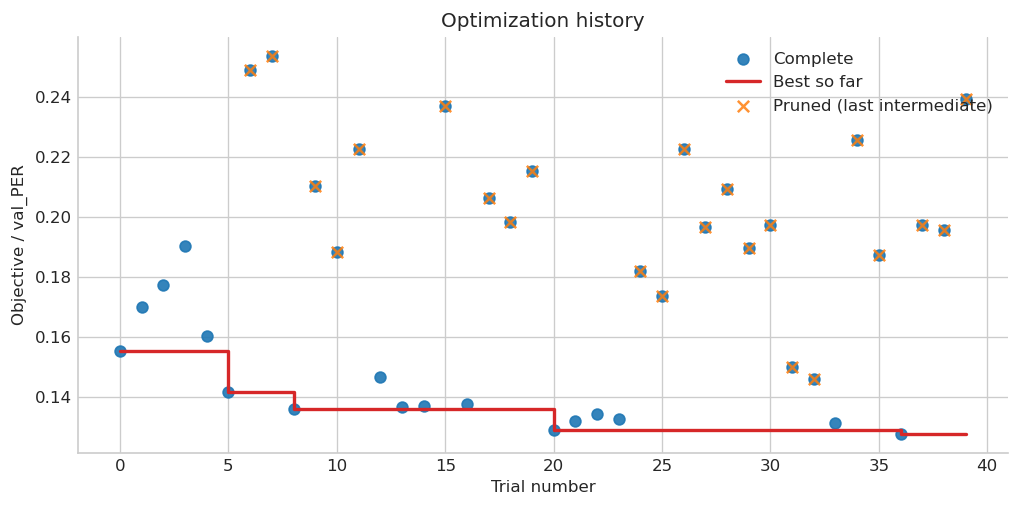

In [4]:
plot_history(rows)


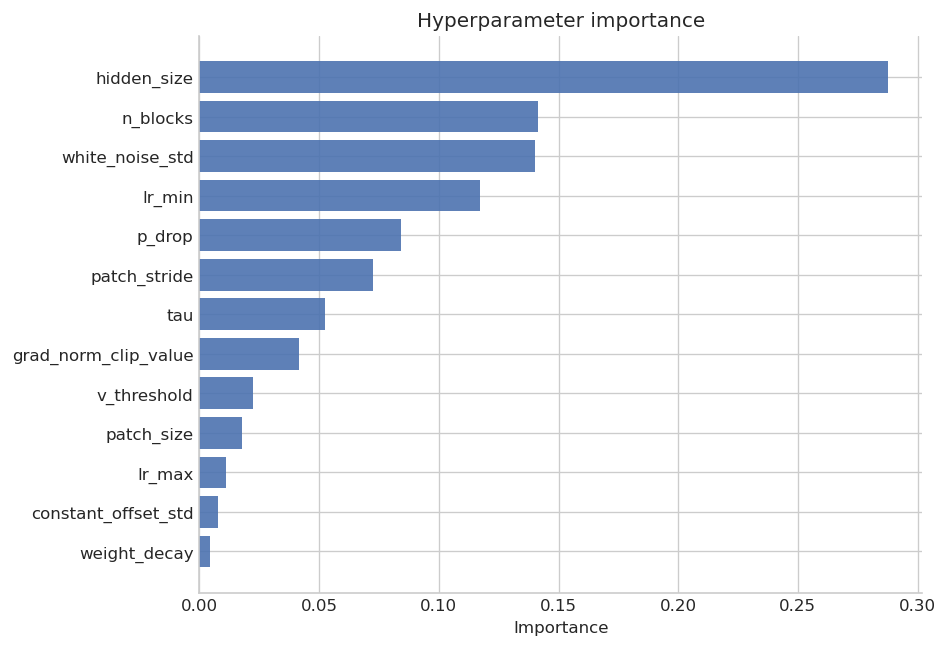

In [5]:
plot_importances(importances)


/tmp/ipykernel_35987/390132741.py:193: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = mpl.cm.get_cmap("viridis_r")


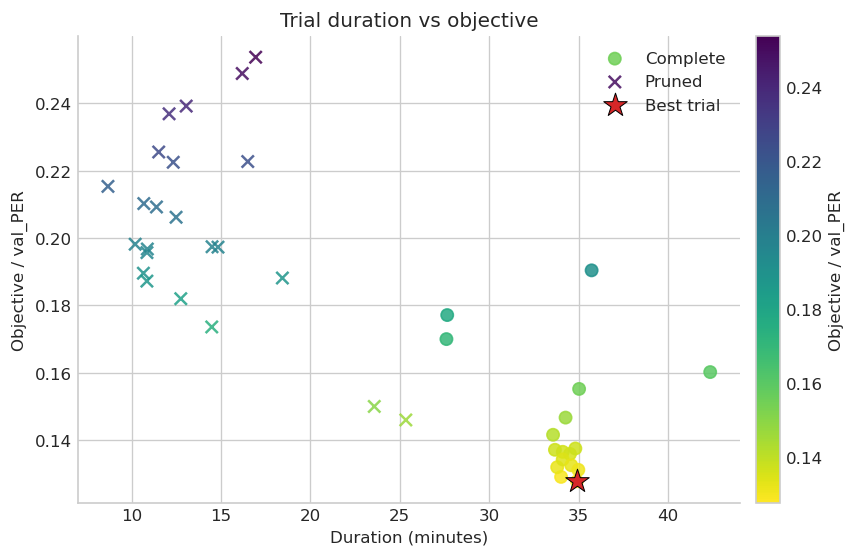

In [6]:
plot_duration_vs_objective(rows, add_colorbar=True)


/tmp/ipykernel_35987/390132741.py:247: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = mpl.cm.get_cmap("viridis_r")


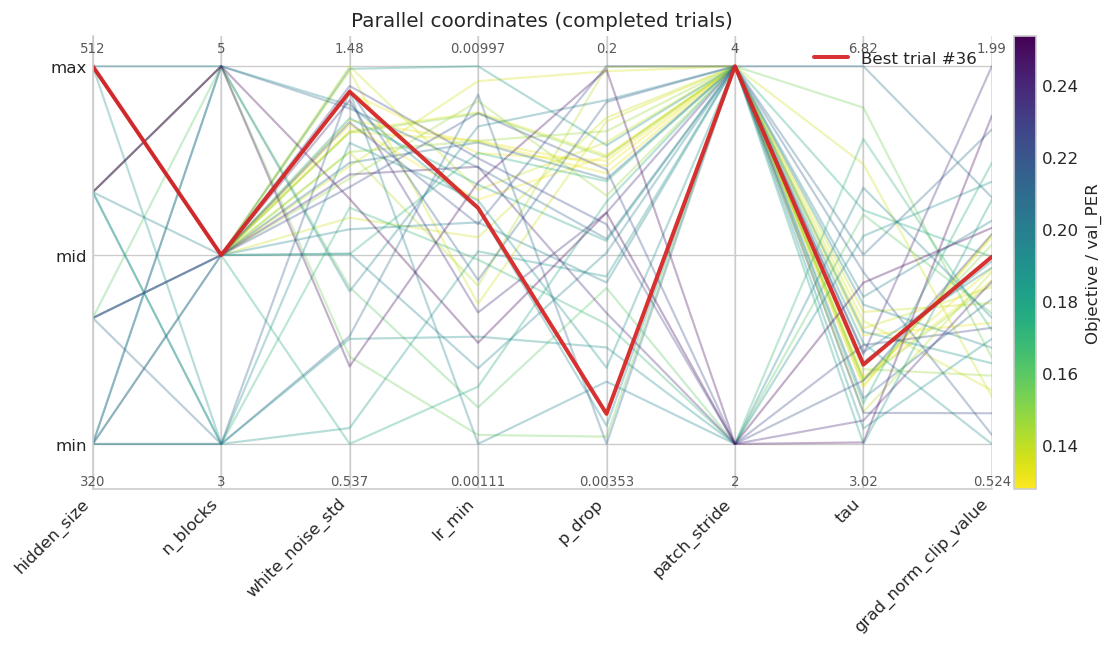

In [7]:
plot_parallel_coordinates(rows, parallel_params, add_colorbar=True)


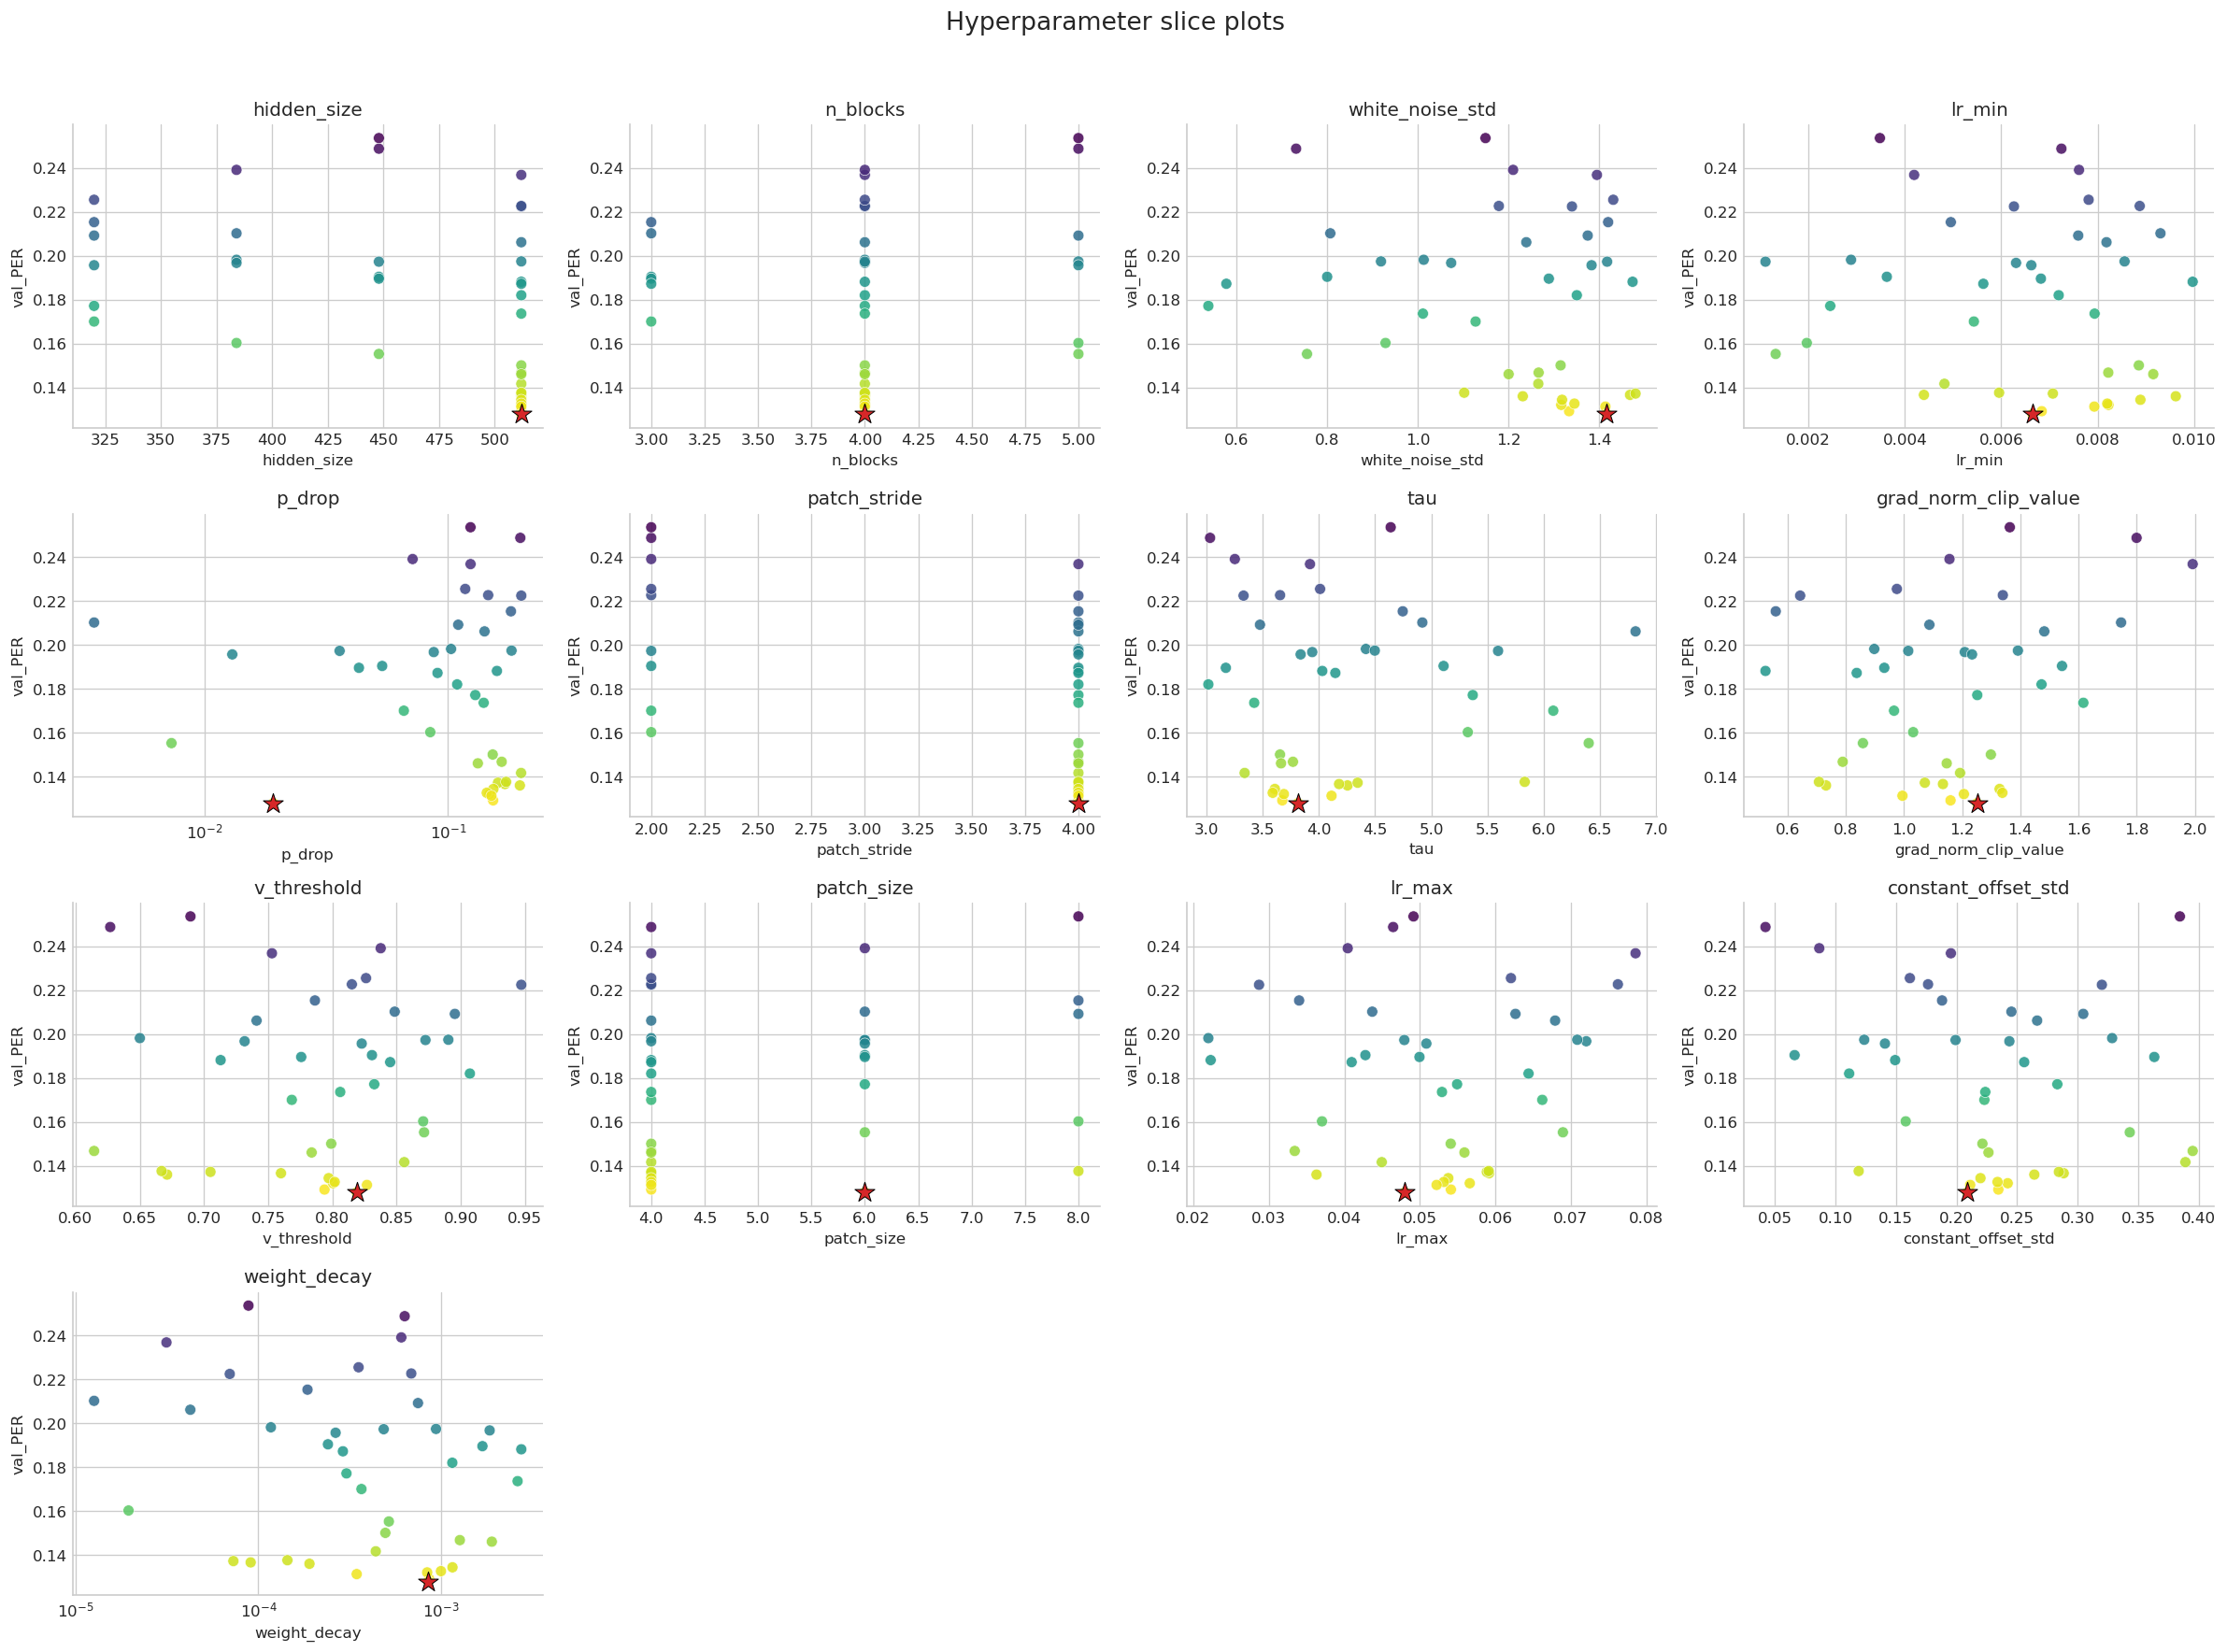

In [8]:
plot_slices(rows, ordered_params, suptitle="Hyperparameter slice plots")


/tmp/ipykernel_35987/390132741.py:193: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = mpl.cm.get_cmap("viridis_r")
/tmp/ipykernel_35987/390132741.py:247: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = mpl.cm.get_cmap("viridis_r")


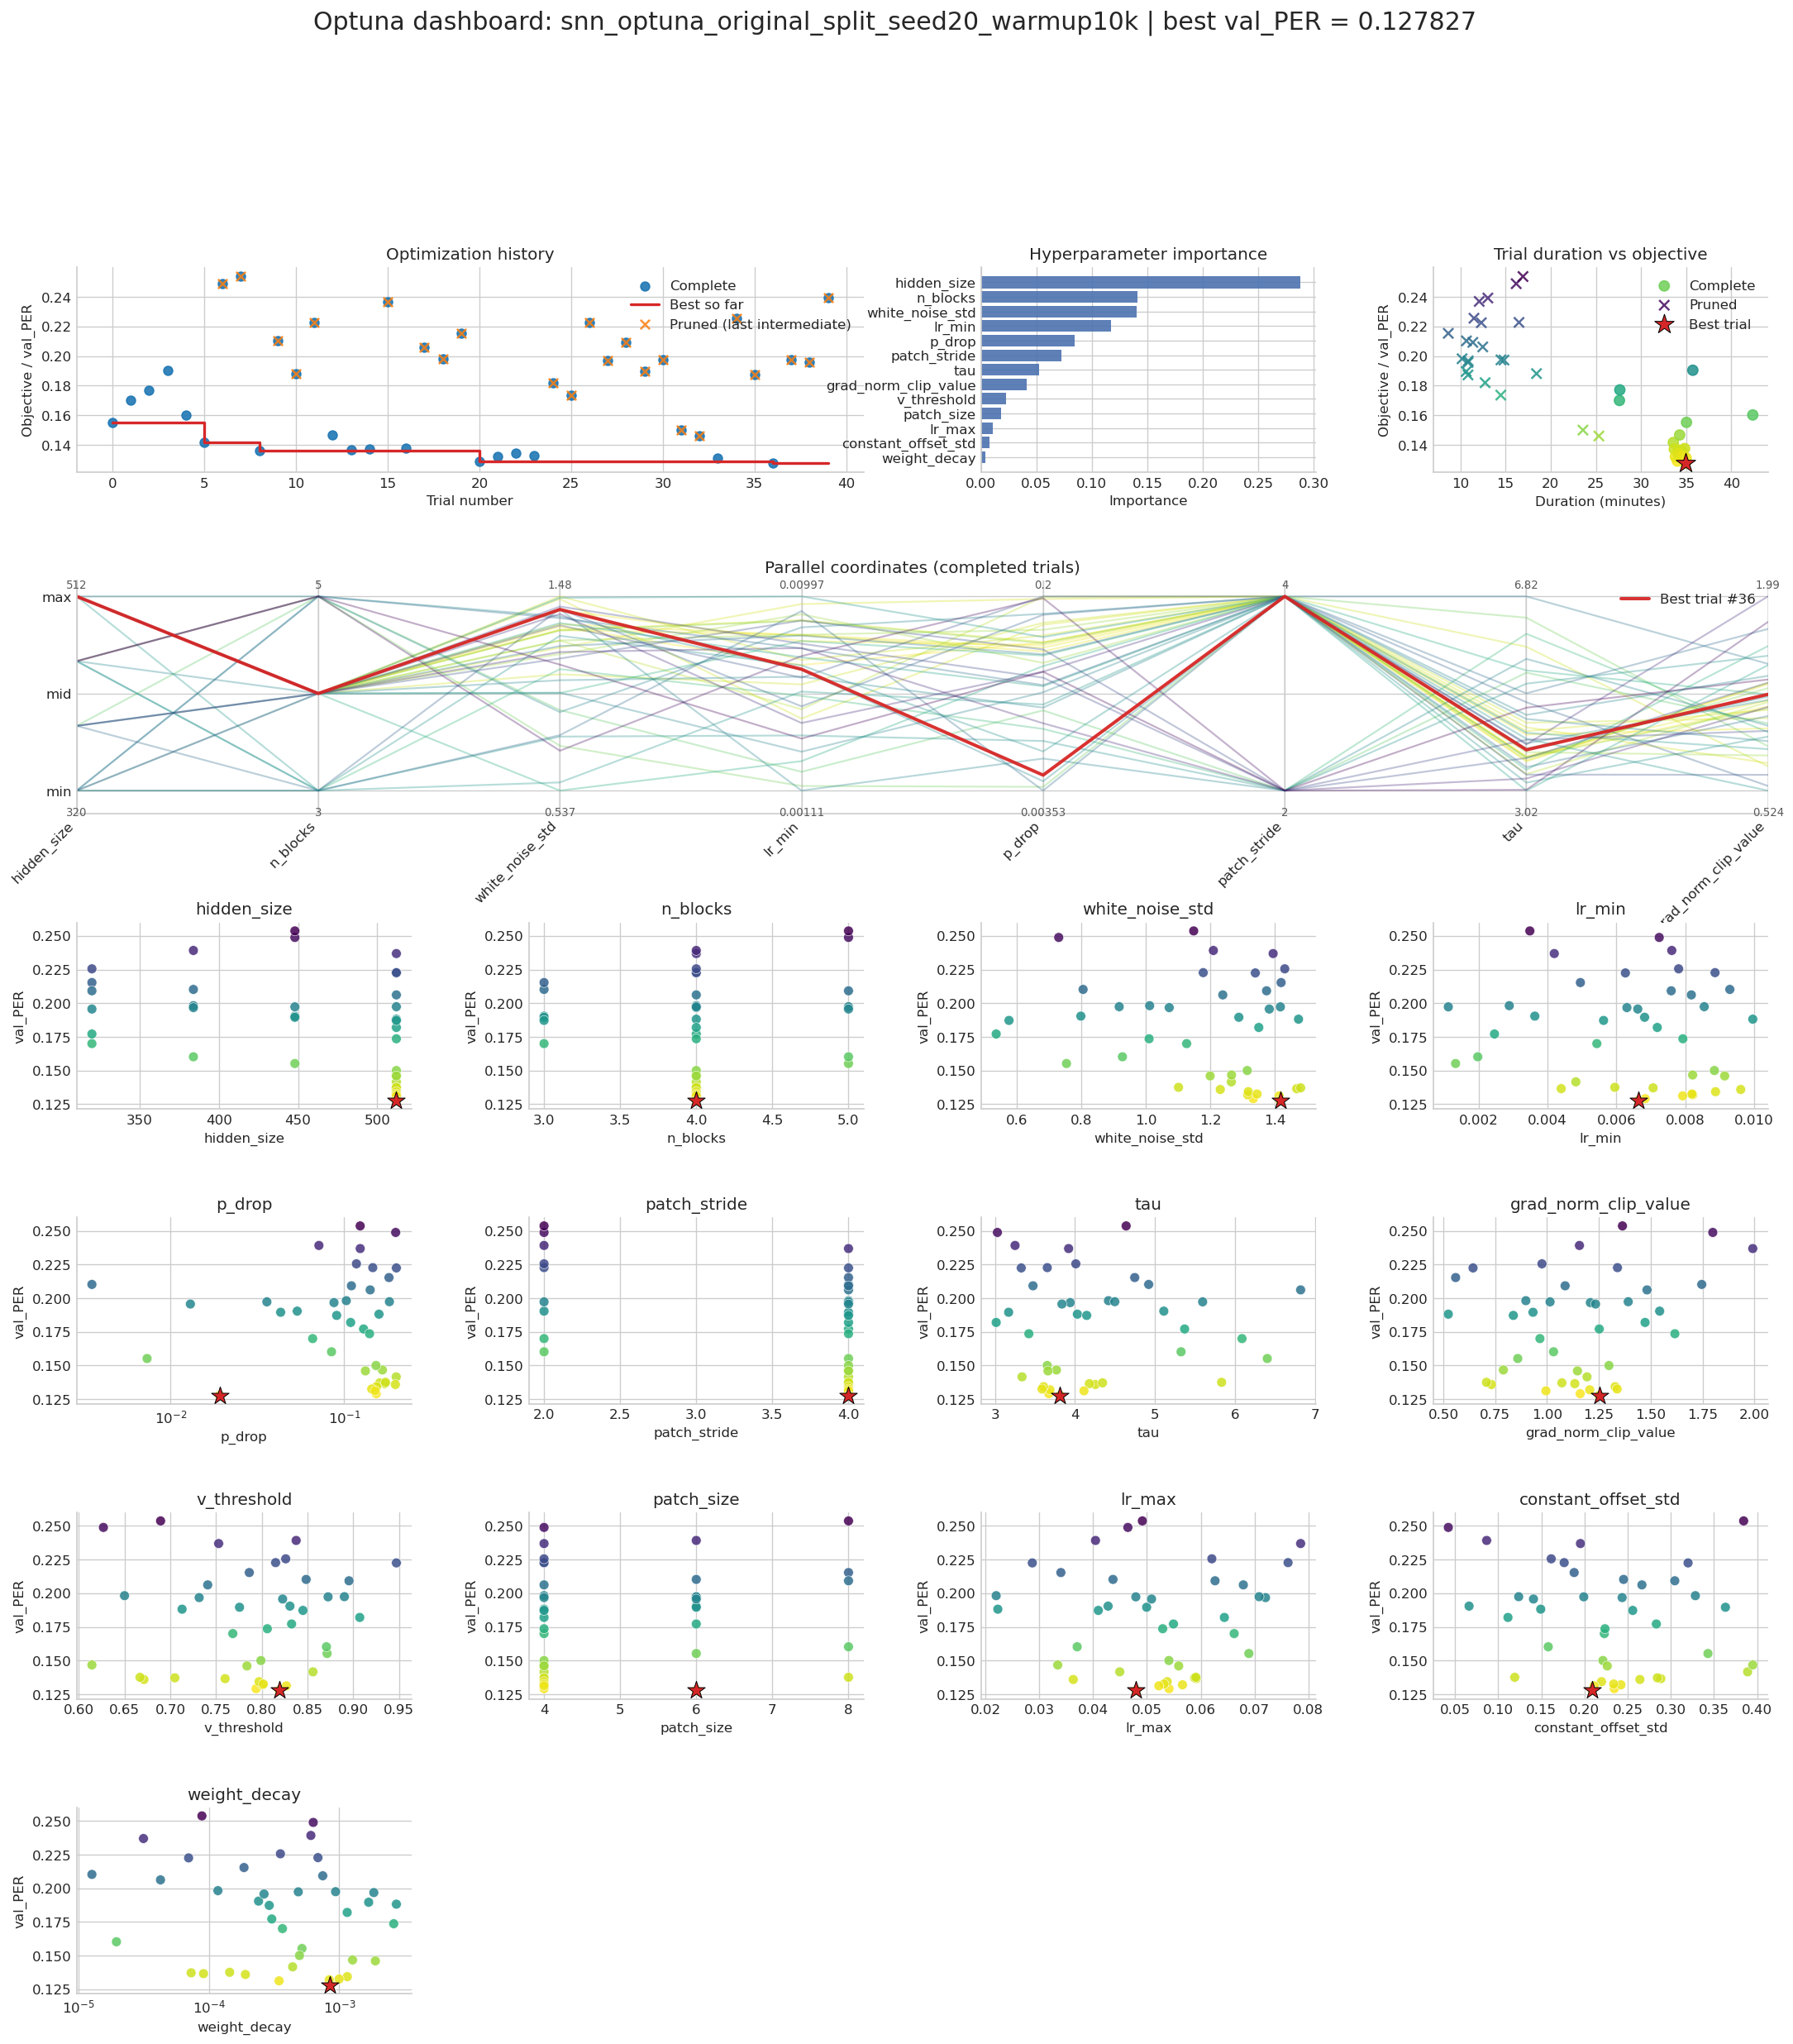

In [9]:
dashboard = build_dashboard(
    rows=rows,
    importances=importances,
    ordered_params=ordered_params,
    parallel_params=parallel_params,
    study_name=study_info["study_name"],
    best_value=best_value,
)
plt.show()


In [10]:
if best_trial is None:
    print("No completed trial is available, so there are no selected hyperparameters to list.")
else:
    print(f"Selected hyperparameters from best trial #{best_trial.number}:")
    for name in sorted(best_trial.params):
        print(f"- {name}: {best_trial.params[name]}")


Selected hyperparameters from best trial #36:
- constant_offset_std: 0.208933456385318
- grad_norm_clip_value: 1.2515714762347308
- hidden_size: 512
- lr_max: 0.04800540246101362
- lr_min: 0.006644965616312739
- n_blocks: 4
- p_drop: 0.019177925237584048
- patch_size: 6
- patch_stride: 4
- tau: 3.8141388544553707
- v_threshold: 0.8189617827585671
- weight_decay: 0.0008501902462504801
- white_noise_std: 1.4163399785649533
